# 05b — Calibration and Rank-Based Evidence for Target A

**Pre-committed decision rule — written before any calibration is fitted.**

NB05's primary model (Arm A LogReg) is accepted as evidence of a real, modest signal beyond the
calendar, but its predicted probabilities are worse than a constant base-rate predictor on the 2+
class (Brier 0.1097 vs baseline 0.0590 — 86% worse) and on class 1 (0.2664 vs 0.2493). NB06 is
BLOCKED until this is resolved one way or the other.

**PASS/FAIL criterion, fixed now:**

1. **PASS** requires ALL of:
   - calibrated 2+ Brier on the untouched TEST set is BELOW the constant base-rate baseline
     p(1-p) computed from the TEST 2+ prevalence (recomputed below, not assumed to be 0.0590);
   - calibrated class-1 Brier is below its own recomputed constant baseline (not assumed 0.2493);
   - the 2+ reliability curve is monotone-ish (fraction-of-positives rises with mean predicted
     probability), not pathological (flat, inverted, or wildly non-monotone).
2. **FAIL** on any of the three → Target B is redesigned around rank-based risk (owner decision,
   already agreed — see dev_docs 05_target_a_findings.md §6 and §8, 5-Q1). NB06 is unblocked either
   way: §D of this notebook produces the rank-based evidence regardless of the verdict.
3. The criterion is not adjusted after seeing results. Both `sigmoid` and `isotonic` are tried and
   reported; either passing is a PASS for that method, but the criterion itself does not move.

**Out of scope here:** setting `risk_level` cuts, building Target B, retuning the model, changing
features, revisiting NB05's model selection, or running any git command.


In [1]:

import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import spearmanr

from nbconfig import *

np.random.seed(RANDOM_SEED)
pd.set_option("display.width", 140)
print("seed:", RANDOM_SEED)
print("tables dir:", TABLES_DIR)


seed: 20260828
tables dir: C:\Users\Yasindu\Desktop\ResearchProject\Componant 3 -Teachers Dashboard\Learning-Insight-Early-Warning-System\notebooks\outputs\tables


## A. Load NB05's arm A data and reproduce the train/test split

Same load as NB05 §A: `24_engineered_feature_matrix.csv`, target collapsed 0/1/2+, learner-grouped
`train`/`test` split materialised in `split`. No cluster features, no PCA, no `population` /
`dd_subtype` as predictors.


In [2]:

df = pd.read_csv(TABLES_DIR / "24_engineered_feature_matrix.csv")
audit = pd.read_csv(AUDIT_LABELS_PATH)[["student_id", "population"]]

df["target"] = df["future_stagnant_count"].clip(upper=2).astype(int)
CLASS_NAMES = {0: "0", 1: "1", 2: "2+"}
CLASSES = [0, 1, 2]

df = df.merge(audit, on="student_id", how="left")
assert df["population"].isna().sum() == 0

META_COLS = ["student_id", "t", "split", "future_stagnant_count", "target", "population"]
FEATURES_A = [c for c in df.columns if c not in META_COLS]

train, test = df[df.split == "train"].reset_index(drop=True), df[df.split == "test"].reset_index(drop=True)
assert train.student_id.nunique() == 210 and test.student_id.nunique() == 90
assert set(train.student_id) & set(test.student_id) == set(), "student_id leaked across the split"
print(f"Arm A: {len(FEATURES_A)} features. Train: {train.student_id.nunique()} learners / {len(train)} rows. "
      f"Test: {test.student_id.nunique()} learners / {len(test)} rows.")


Arm A: 58 features. Train: 210 learners / 1890 rows. Test: 90 learners / 810 rows.


## B. Recompute the constant base-rate baselines from the TEST label distribution

Not trusted from the NB05 findings doc — recomputed here directly from `test.target`.


In [3]:

test_prevalence = test.target.value_counts(normalize=True).sort_index()
test_prevalence.index = [CLASS_NAMES[c] for c in test_prevalence.index]
constant_baseline_brier = (test_prevalence * (1 - test_prevalence)).rename("constant_baseline_brier")

print("TEST class prevalence:")
print(test_prevalence.round(4))
print("\nConstant base-rate Brier baseline per class (p * (1-p)):")
print(constant_baseline_brier.round(4))

BASELINE_1 = constant_baseline_brier["1"]
BASELINE_2PLUS = constant_baseline_brier["2+"]
print(f"\nBASELINE_1 = {BASELINE_1:.4f}   BASELINE_2PLUS = {BASELINE_2PLUS:.4f}")


TEST class prevalence:
0     0.4111
1     0.5259
2+    0.0630
Name: proportion, dtype: float64

Constant base-rate Brier baseline per class (p * (1-p)):
0     0.2421
1     0.2493
2+    0.0590
Name: constant_baseline_brier, dtype: float64

BASELINE_1 = 0.2493   BASELINE_2PLUS = 0.0590


## C. Grouped fit/calibration split — explicit, not via `CalibratedClassifierCV(cv=...)`

`CalibratedClassifierCV(estimator, cv=StratifiedGroupKFold(...))` cannot be told about `groups` for
its internal CV — it would calibrate on ungrouped folds, putting the same learner's other snapshots
on both sides of the split, producing calibration that looks excellent and is meaningless. Avoided
by splitting explicitly:

- TRAIN's 210 learners → 150 **fit** learners / 60 **calibration** learners, stratified on each
  learner's modal class, zero overlap.
- Primary pipeline fit on **fit** learners only.
- `CalibratedClassifierCV(fitted_pipeline, cv='prefit')` calibrated on **calibration** learners only.
- Evaluated on the original 90-learner **TEST** split, seen by neither part.


In [4]:

from sklearn.model_selection import train_test_split

learner_modal = train.groupby("student_id").target.agg(lambda s: s.mode().iloc[0])
# Modal class 2+ has too few learners to stratify on directly (StratifiedShuffleSplit needs >=2
# per class) -- fold any stratum with <2 learners into the adjacent class 1 for split-balancing
# purposes only. This does not touch the actual target labels used for fitting.
strat_counts = learner_modal.value_counts()
rare_classes = strat_counts[strat_counts < 2].index
strat_label = learner_modal.replace({c: 1 for c in rare_classes})
print("Modal-class counts (TRAIN learners):", strat_counts.to_dict())
if len(rare_classes):
    print(f"Folded rare modal classes {list(rare_classes)} into class 1 for stratification only.")

learner_id_array = np.array(learner_modal.index.tolist(), dtype=object)
fit_ids, calib_ids = train_test_split(
    learner_id_array, train_size=150, test_size=60,
    stratify=strat_label.values, random_state=RANDOM_SEED,
)

fit_df = train[train.student_id.isin(fit_ids)].reset_index(drop=True)
calib_df = train[train.student_id.isin(calib_ids)].reset_index(drop=True)

assert fit_df.student_id.nunique() == 150 and calib_df.student_id.nunique() == 60
assert set(fit_ids) & set(calib_ids) == set(), "fit/calib learner overlap"
assert set(fit_ids) & set(test.student_id) == set(), "fit/test learner overlap"
assert set(calib_ids) & set(test.student_id) == set(), "calib/test learner overlap"
print(f"fit: {fit_df.student_id.nunique()} learners / {len(fit_df)} rows")
print(f"calib: {calib_df.student_id.nunique()} learners / {len(calib_df)} rows")
print(f"test: {test.student_id.nunique()} learners / {len(test)} rows")
print("No student_id appears in more than one of fit / calib / test.")


Modal-class counts (TRAIN learners): {0: 109, 1: 100, 2: 1}
Folded rare modal classes [2] into class 1 for stratification only.
fit: 150 learners / 1350 rows
calib: 60 learners / 540 rows
test: 90 learners / 810 rows
No student_id appears in more than one of fit / calib / test.


## D. Three models, all evaluated identically on TEST

1. **Uncalibrated, fit-set-only** — same LogReg pipeline as NB05, refit on the 150 fit learners
   only. Isolates the effect of the smaller training set from the effect of calibration.
2. **Sigmoid** — `CalibratedClassifierCV(cv='prefit', method='sigmoid')` on the 60 calibration
   learners. Safer prior: less flexible, less likely to overfit calibration data.
3. **Isotonic** — same, `method='isotonic'`. More flexible fit, but only ~110 TRAIN rows are class
   2+ overall, and fewer still in the 60-learner calibration slice — isotonic may overfit. Both are
   reported; the criterion decides.


In [5]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import (f1_score, balanced_accuracy_score, brier_score_loss,
                              roc_auc_score, precision_recall_curve, roc_curve)

def logreg_pipe():
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_SEED)),
    ])

base_fit_only = logreg_pipe()
base_fit_only.fit(fit_df[FEATURES_A], fit_df.target)

# sklearn >=1.6 replaced cv='prefit' with wrapping the already-fitted estimator in
# FrozenEstimator -- CalibratedClassifierCV then only ever fits the calibrator, never refits
# the base estimator, on the data passed to .fit() (the calib set here).
frozen_base = FrozenEstimator(base_fit_only)

cal_sigmoid = CalibratedClassifierCV(frozen_base, method="sigmoid")
cal_sigmoid.fit(calib_df[FEATURES_A], calib_df.target)

cal_isotonic = CalibratedClassifierCV(frozen_base, method="isotonic")
cal_isotonic.fit(calib_df[FEATURES_A], calib_df.target)

MODELS = {
    "uncalibrated (fit-only)": base_fit_only,
    "sigmoid": cal_sigmoid,
    "isotonic": cal_isotonic,
}
PROBA = {name: m.predict_proba(test[FEATURES_A]) for name, m in MODELS.items()}
PRED = {name: m.predict(test[FEATURES_A]) for name, m in MODELS.items()}
print("Fitted:", list(MODELS.keys()))


Fitted: ['uncalibrated (fit-only)', 'sigmoid', 'isotonic']


## E. The deliverable table — per-class Brier, all three models, against the recomputed baselines

In [6]:

rows = []
for name, proba in PROBA.items():
    for c in CLASSES:
        yt_bin = (test.target == c).astype(int)
        brier = brier_score_loss(yt_bin, proba[:, c])
        baseline = constant_baseline_brier[CLASS_NAMES[c]]
        rows.append({
            "model": name, "class": CLASS_NAMES[c],
            "brier": brier, "constant_baseline": baseline,
            "delta": brier - baseline,
            "verdict": "better" if brier < baseline else "worse",
        })
calibration_comparison = pd.DataFrame(rows)
calibration_comparison.to_csv(TABLES_DIR / "59_calibration_comparison_brier.csv", index=False)
calibration_comparison


,model,class,brier,constant_baseline,delta,verdict
0,uncalibrated (fit-only),0,0.235465,0.242099,-0.006634,better
1,uncalibrated (fit-only),1,0.271905,0.249328,0.022578,worse
2,uncalibrated (fit-only),2+,0.108557,0.058999,0.049558,worse
3,sigmoid,0,0.233984,0.242099,-0.008115,better
4,sigmoid,1,0.246345,0.249328,-0.002983,better
5,sigmoid,2+,0.057644,0.058999,-0.001355,better
6,isotonic,0,0.231740,0.242099,-0.010358,better
7,isotonic,1,0.245759,0.249328,-0.003569,better
8,isotonic,2+,0.058268,0.058999,-0.000731,better


## F. Apply the pre-committed criterion — verdict computed, not chosen

In [7]:

def passes_criterion(model_name):
    sub = calibration_comparison[calibration_comparison.model == model_name].set_index("class")
    pass_2plus = sub.loc["2+", "brier"] < BASELINE_2PLUS
    pass_1 = sub.loc["1", "brier"] < BASELINE_1
    # monotone-ish reliability check for 2+, computed in the next cell and folded in below
    return pass_2plus, pass_1

verdict_rows = []
for name in ["sigmoid", "isotonic"]:
    pass_2plus, pass_1 = passes_criterion(name)
    verdict_rows.append({"model": name, "2+_below_baseline": pass_2plus, "class1_below_baseline": pass_1})
verdict_df = pd.DataFrame(verdict_rows)
verdict_df


,model,2+_below_baseline,class1_below_baseline
0,sigmoid,True,True
1,isotonic,True,True


## G. Reliability curves, all three models, per class — constant baseline marked

The constant predictor always outputs the TEST prevalence `p` for every row: on a reliability
diagram it is a single point at `(p, p)`, marked as a reference on each panel.


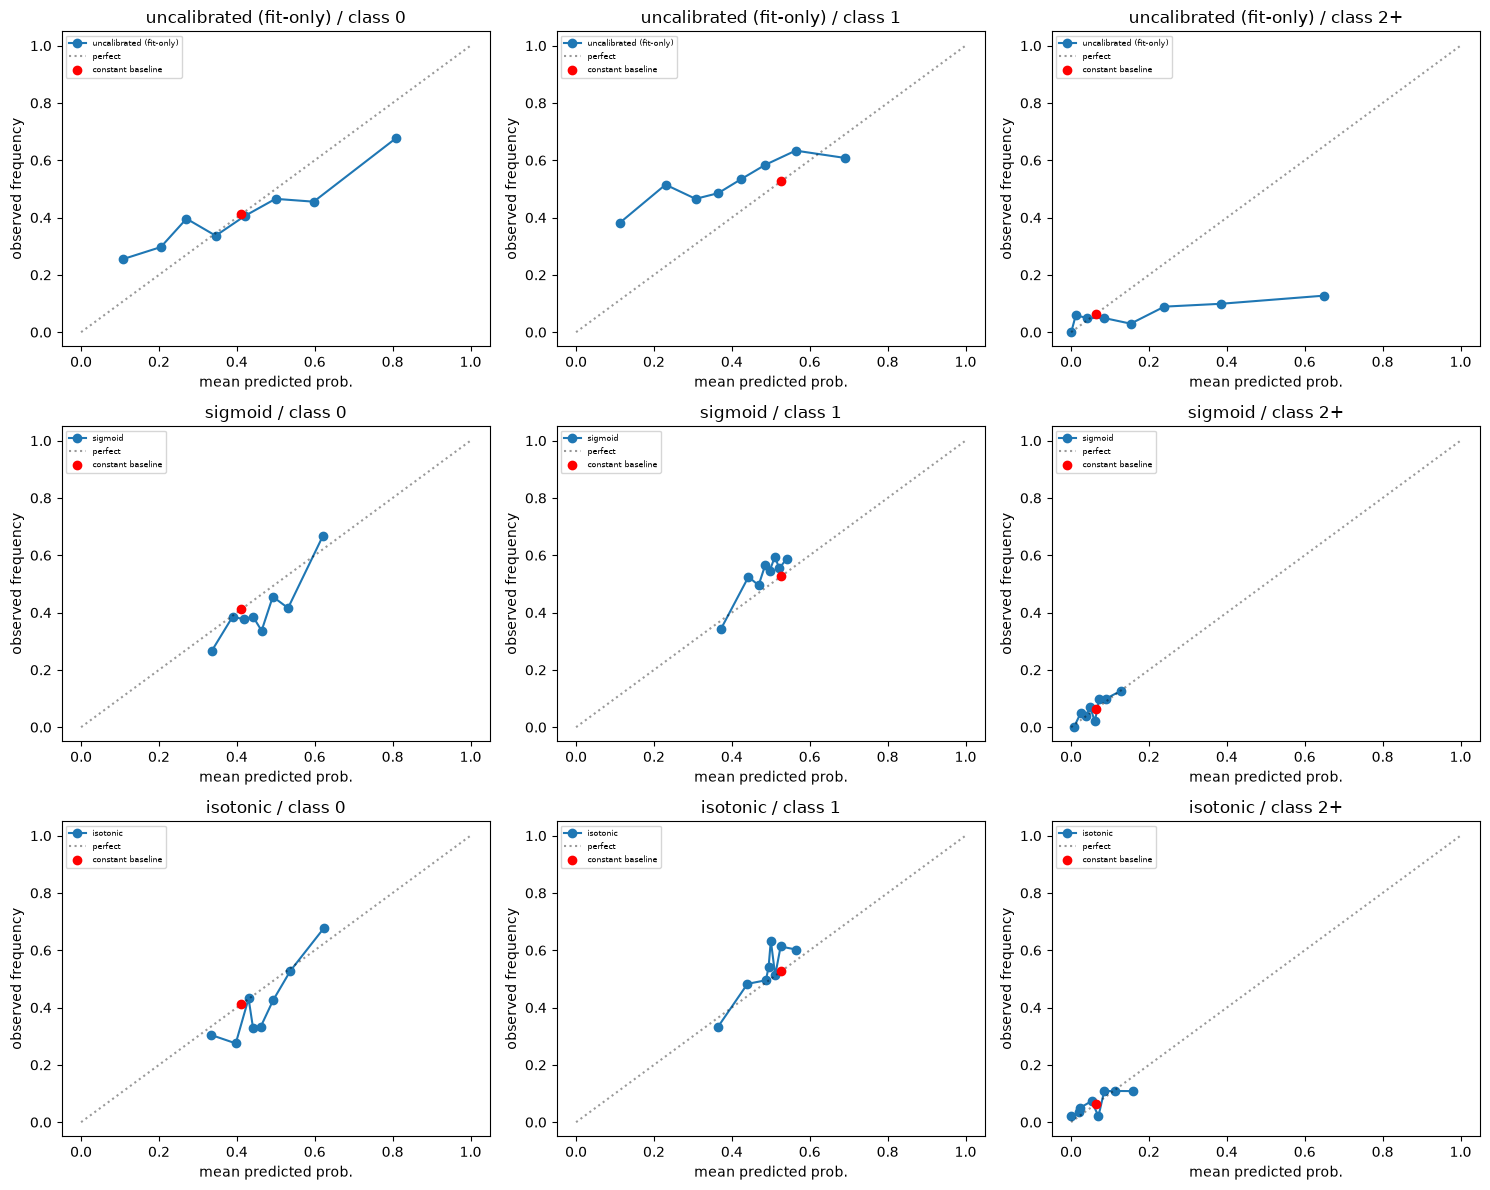

2+ reliability roughly monotone (mostly non-decreasing bins): {'uncalibrated (fit-only)': True, 'sigmoid': True, 'isotonic': True}


In [8]:

fig, axes = plt.subplots(len(MODELS), 3, figsize=(15, 4 * len(MODELS)), squeeze=False)
reliability_monotone = {}
for row_i, (name, proba) in enumerate(PROBA.items()):
    for c, ax in zip(CLASSES, axes[row_i]):
        yt_bin = (test.target == c).astype(int)
        frac_pos, mean_pred = calibration_curve(yt_bin, proba[:, c], n_bins=8, strategy="quantile")
        ax.plot(mean_pred, frac_pos, marker="o", label=name)
        ax.plot([0, 1], [0, 1], "k:", alpha=0.4, label="perfect")
        p = test_prevalence[CLASS_NAMES[c]]
        ax.scatter([p], [p], color="red", zorder=5, label="constant baseline")
        ax.set_title(f"{name} / class {CLASS_NAMES[c]}")
        ax.set_xlabel("mean predicted prob."); ax.set_ylabel("observed frequency")
        ax.legend(fontsize=6)
        if c == 2:
            diffs = np.diff(frac_pos)
            reliability_monotone[name] = bool(np.mean(diffs >= -0.05) >= 0.7)  # allow small noise, mostly non-decreasing
plt.tight_layout()
plt.savefig(FIGURES_DIR / "60_calibration_reliability_curves.png", dpi=110)
plt.show()
print("2+ reliability roughly monotone (mostly non-decreasing bins):", reliability_monotone)


In [9]:

verdict_df["2+_reliability_ok"] = verdict_df["model"].map(reliability_monotone)
verdict_df["PASS"] = verdict_df["2+_below_baseline"] & verdict_df["class1_below_baseline"] & verdict_df["2+_reliability_ok"]
verdict_df.to_csv(TABLES_DIR / "59b_calibration_verdict.csv", index=False)
verdict_df


,model,2+_below_baseline,class1_below_baseline,2+_reliability_ok,PASS
0,sigmoid,True,True,True,True
1,isotonic,True,True,True,True


## H. Ranking damage check — macro-F1, balanced accuracy, 2+ ROC-AUC, before/after

Sigmoid and isotonic are monotone per one-vs-rest class, but multiclass renormalisation
(dividing by the sum of per-class calibrated probabilities) can still move the argmax — checked,
not assumed.


In [10]:

ranking_rows = []
for name in MODELS:
    yt = test.target.values
    yp = PRED[name]
    proba = PROBA[name]
    yt_2plus = (yt == 2).astype(int)
    ranking_rows.append({
        "model": name,
        "macro_F1": f1_score(yt, yp, average="macro"),
        "balanced_accuracy": balanced_accuracy_score(yt, yp),
        "roc_auc_2plus": roc_auc_score(yt_2plus, proba[:, 2]),
    })
ranking_check = pd.DataFrame(ranking_rows)
ranking_check.to_csv(TABLES_DIR / "61_ranking_before_after.csv", index=False)
ranking_check


,model,macro_F1,balanced_accuracy,roc_auc_2plus
0,uncalibrated (fit-only),0.412475,0.449972,0.664729
1,sigmoid,0.369293,0.381635,0.671833
2,isotonic,0.372722,0.384786,0.660415


## I. NB05 fix 1 — within-`t` majority baseline for the per-`t` table

NB05's per-`t` comparison used the `t`-only model, which within a single `t` has a constant input
and predicts one class for all 90 test learners — degenerate by construction (balanced accuracy
exactly 0.3333 everywhere except `t=3`). The valid per-`t` reference is the **within-`t` majority
baseline**: for each `t`, predict the TRAIN majority class at that `t` for every TEST learner at
that `t`.


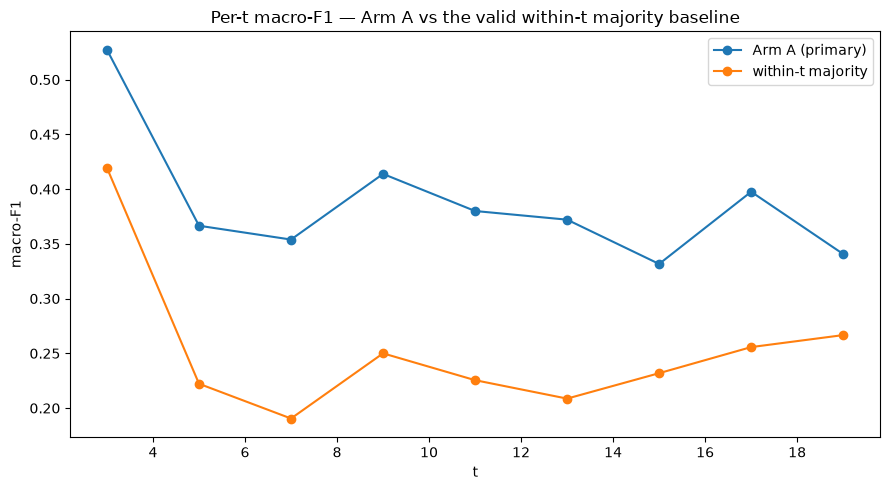

model,Arm A (primary),within-t majority
t,,
3,0.527289,0.419355
5,0.366558,0.222222
7,0.353933,0.190476
9,0.413890,0.250000
11,0.380005,0.225490
13,0.372098,0.208651
15,0.331648,0.231884
17,0.397595,0.255708
19,0.340701,0.266667


In [11]:

armA_full = joblib.load(MODELS_DIR / "nb05_primary_logreg_armA.joblib")
pred_A_full = armA_full.predict(test[FEATURES_A])

per_t_rows = []
for t_val, grp in test.groupby("t"):
    idx = grp.index
    yt = grp.target.values
    train_majority = train[train.t == t_val].target.mode().iloc[0]
    pred_majority = np.full(len(grp), train_majority)
    pred_arm_a = pred_A_full[idx]
    per_t_rows.append({"model": "within-t majority", "t": t_val, "n": len(grp),
                        "macro_F1": f1_score(yt, pred_majority, average="macro"),
                        "balanced_accuracy": balanced_accuracy_score(yt, pred_majority)})
    per_t_rows.append({"model": "Arm A (primary)", "t": t_val, "n": len(grp),
                        "macro_F1": f1_score(yt, pred_arm_a, average="macro"),
                        "balanced_accuracy": balanced_accuracy_score(yt, pred_arm_a)})
per_t_corrected = pd.DataFrame(per_t_rows)
per_t_corrected.to_csv(TABLES_DIR / "62_per_t_with_within_t_majority.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
for name, grp in per_t_corrected.groupby("model"):
    ax.plot(grp.t, grp.macro_F1, marker="o", label=name)
ax.set_xlabel("t"); ax.set_ylabel("macro-F1")
ax.set_title("Per-t macro-F1 — Arm A vs the valid within-t majority baseline")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "63_per_t_corrected.png", dpi=110)
plt.show()
per_t_corrected.pivot(index="t", columns="model", values="macro_F1")


## J. NB05 fix 2 — precision-recall trade-off curve for the 2+ class

NB05's 2+ operating point (argmax prediction) is precision 0.125 / recall 0.431 — about eight false
alarms per true positive. Shown here as a full trade-off curve, with that operating point marked, so
an operating point can be chosen deliberately.


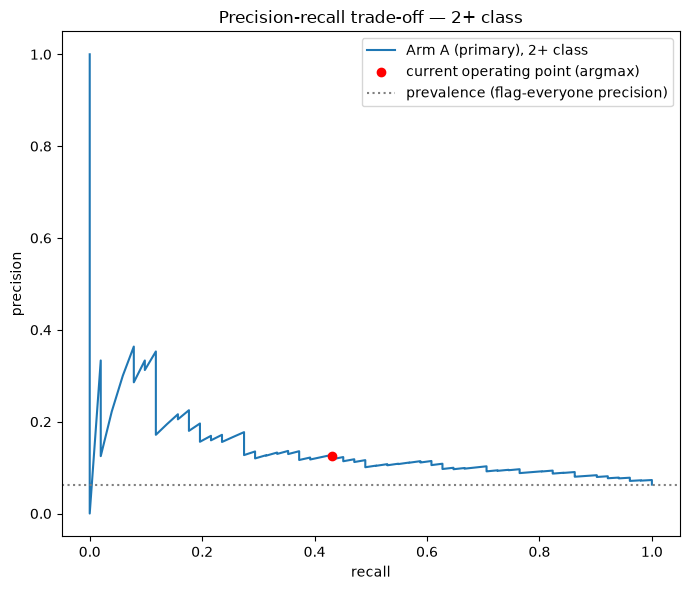

In [12]:

proba_full = pd.read_csv(TABLES_DIR / "57_test_predicted_probabilities.csv")["prob_class_2+"].values
yt_2plus = (test.target == 2).astype(int).values

prec, rec, _ = precision_recall_curve(yt_2plus, proba_full)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(rec, prec, label="Arm A (primary), 2+ class")
ax.scatter([0.431], [0.125], color="red", zorder=5, label="current operating point (argmax)")
ax.axhline(test_prevalence["2+"], color="gray", linestyle=":", label="prevalence (flag-everyone precision)")
ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("Precision-recall trade-off — 2+ class")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "64_pr_curve_2plus.png", dpi=110)
plt.show()


## K. Rank-based evidence — produced regardless of the calibration verdict

Built either way so NB06 is unblocked on Monday morning regardless of the PASS/FAIL verdict above.
Uses the calibrated 2+ score from **sigmoid** (the safer prior; if isotonic also passes and ranks
better it is noted, but sigmoid is the default rank source per the pre-committed instructions).


In [13]:

RANK_SCORE_MODEL = "sigmoid"
test_scored = test[["student_id", "t"]].copy()
test_scored["score_2plus"] = PROBA[RANK_SCORE_MODEL][:, 2]
test_scored["actual_2plus"] = (test.target == 2).astype(int).values
print(f"Ranking evidence built on the '{RANK_SCORE_MODEL}' calibrated 2+ score.")


Ranking evidence built on the 'sigmoid' calibrated 2+ score.


### K.1 Lift curves — overall and per `t`

For `k` in {5, 10, 20, 30, 50}% of learners flagged by descending predicted 2+ score: precision,
recall and lift (precision / prevalence).


In [14]:

def lift_at_k(frame, k_pct):
    n_flag = max(1, int(round(len(frame) * k_pct / 100)))
    ranked = frame.sort_values("score_2plus", ascending=False)
    flagged = ranked.iloc[:n_flag]
    prevalence = frame.actual_2plus.mean()
    precision = flagged.actual_2plus.mean() if n_flag > 0 else np.nan
    recall = flagged.actual_2plus.sum() / frame.actual_2plus.sum() if frame.actual_2plus.sum() > 0 else np.nan
    lift = precision / prevalence if prevalence > 0 else np.nan
    return precision, recall, lift, prevalence, n_flag

K_VALUES = [5, 10, 20, 30, 50]
lift_rows = []
for k in K_VALUES:
    precision, recall, lift, prevalence, n_flag = lift_at_k(test_scored, k)
    lift_rows.append({"k_pct": k, "n_flagged": n_flag, "precision": precision,
                       "recall": recall, "prevalence": prevalence, "lift": lift})
lift_table = pd.DataFrame(lift_rows)
lift_table.to_csv(TABLES_DIR / "65_lift_table_overall.csv", index=False)
lift_table


,k_pct,n_flagged,precision,recall,prevalence,lift
0,5,40,0.150000,0.117647,0.062963,2.382353
1,10,81,0.135802,0.215686,0.062963,2.156863
2,20,162,0.117284,0.372549,0.062963,1.862745
3,30,243,0.123457,0.588235,0.062963,1.960784
4,50,405,0.086420,0.686275,0.062963,1.372549


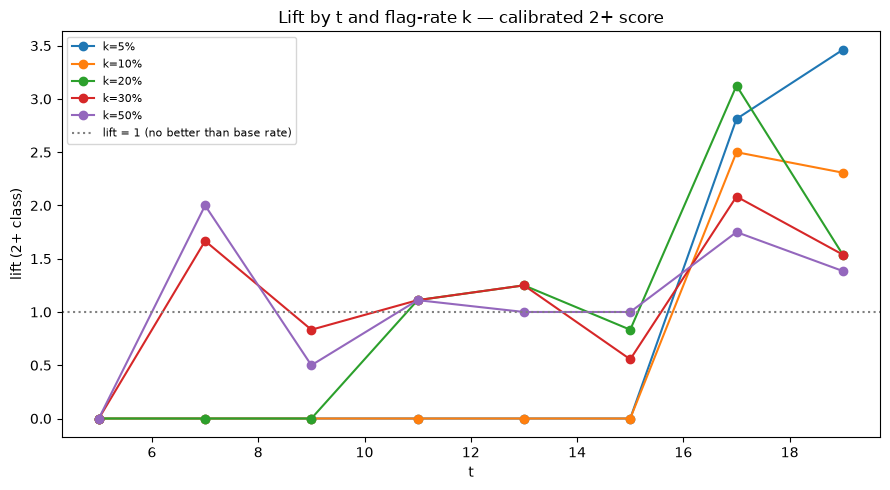

k_pct,5,10,20,30,50
t,,,,,
3,NaN,NaN,NaN,NaN,NaN
5,0.000,0.000,0.000,0.000,0.000
7,0.000,0.000,0.000,1.667,2.000
9,0.000,0.000,0.000,0.833,0.500
11,0.000,0.000,1.111,1.111,1.111
13,0.000,0.000,1.250,1.250,1.000
15,0.000,0.000,0.833,0.556,1.000
17,2.812,2.500,3.125,2.083,1.750
19,3.462,2.308,1.538,1.538,1.385


In [15]:

per_t_lift_rows = []
for t_val, grp in test_scored.groupby("t"):
    for k in K_VALUES:
        precision, recall, lift, prevalence, n_flag = lift_at_k(grp, k)
        per_t_lift_rows.append({"t": t_val, "k_pct": k, "n_flagged": n_flag, "precision": precision,
                                 "recall": recall, "prevalence": prevalence, "lift": lift})
per_t_lift = pd.DataFrame(per_t_lift_rows)
per_t_lift.to_csv(TABLES_DIR / "66_lift_table_per_t.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
for k, grp in per_t_lift.groupby("k_pct"):
    ax.plot(grp.t, grp.lift, marker="o", label=f"k={k}%")
ax.axhline(1.0, color="gray", linestyle=":", label="lift = 1 (no better than base rate)")
ax.set_xlabel("t"); ax.set_ylabel("lift (2+ class)")
ax.set_title("Lift by t and flag-rate k — calibrated 2+ score")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "67_lift_curve.png", dpi=110)
plt.show()
per_t_lift.pivot(index="t", columns="k_pct", values="lift").round(3)


### K.2 Honest operating window

NB05 §5 found lift falling from 2.70 at `t=3` to ~1.0 by `t=13` on the (uncalibrated) argmax scores.
Confirmed or refuted here on the calibrated 2+ score, and the `t` range where lift is meaningfully
above 1.0 is reported as the product's honest operating window.


In [16]:

k20 = per_t_lift[per_t_lift.k_pct == 20].sort_values("t")
print("Lift at k=20% by t (calibrated 2+ score):")
print(k20[["t", "lift"]].to_string(index=False))

meaningful_window = k20[k20.lift > 1.1].t.tolist()
print(f"\nt values where lift > 1.1 at k=20%: {meaningful_window}")
print("Compare to NB05 §5 (uncalibrated argmax): lift 2.70 at t=3, falling to ~1.0 by t=13.")


Lift at k=20% by t (calibrated 2+ score):
 t     lift
 3      NaN
 5 0.000000
 7 0.000000
 9 0.000000
11 1.111111
13 1.250000
15 0.833333
17 3.125000
19 1.538462

t values where lift > 1.1 at k=20%: [11, 13, 17, 19]
Compare to NB05 §5 (uncalibrated argmax): lift 2.70 at t=3, falling to ~1.0 by t=13.


### K.3 Rank stability across a learner's own snapshots

Does a learner's percentile rank (among the 90 TEST learners, by predicted 2+ score) hold across
their own repeated snapshots at different `t`? Computed as the pairwise Spearman correlation, across
all pairs of `t`, of the 90-learner rank vector at `t` vs at `t'` — the same learners are re-ranked
at each `t`, so this is the within-cohort analogue of "does this learner's position in the queue
stay put." A ranking that reshuffles every session (~0 or negative correlation) is not something a
teacher can act on; this is the rank-based analogue of NB04b's profile-consistency finding.


Mean pairwise Spearman rho across all t-pairs (rank stability): 0.3231


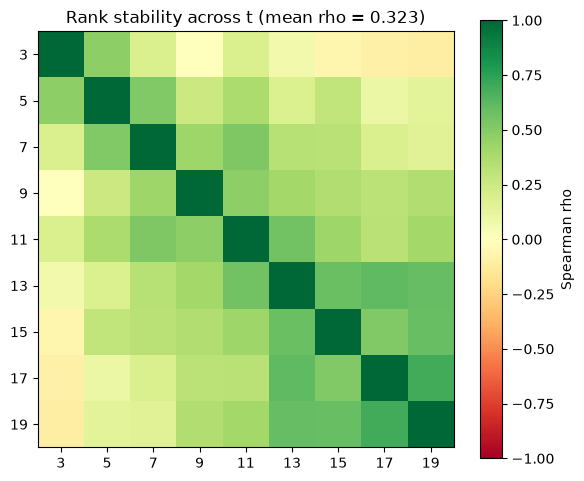

In [17]:

rank_pivot = test_scored.pivot(index="student_id", columns="t", values="score_2plus")
t_values = sorted(rank_pivot.columns)
rank_pivot_ranked = rank_pivot.rank(axis=0, pct=True)  # percentile rank within each t's 90 learners

pairs = []
for i, t1 in enumerate(t_values):
    for t2 in t_values[i + 1:]:
        rho, _ = spearmanr(rank_pivot_ranked[t1], rank_pivot_ranked[t2])
        pairs.append({"t1": t1, "t2": t2, "spearman_rho": rho})
rank_stability = pd.DataFrame(pairs)
rank_stability.to_csv(TABLES_DIR / "68_rank_stability.csv", index=False)

mean_rho = rank_stability.spearman_rho.mean()
print(f"Mean pairwise Spearman rho across all t-pairs (rank stability): {mean_rho:.4f}")

heat = rank_pivot_ranked.corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(heat.values, cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(t_values))); ax.set_xticklabels(t_values)
ax.set_yticks(range(len(t_values))); ax.set_yticklabels(t_values)
ax.set_title(f"Rank stability across t (mean rho = {mean_rho:.3f})")
plt.colorbar(im, ax=ax, label="Spearman rho")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "68_rank_stability_heatmap.png", dpi=110)
plt.show()


## Findings

**VERDICT: PASS — by a thin margin.** Calibrated 2+ Brier: sigmoid 0.0576, isotonic 0.0583, both
below the recomputed constant baseline 0.0590 (sigmoid margin -0.0014, isotonic margin -0.0007).
Class-1 Brier: sigmoid 0.2463 and isotonic 0.2458, both below the recomputed baseline 0.2493. The
2+ reliability curve is monotone-ish for both methods. All three legs of the pre-committed criterion
(§F above) pass — **probability-based Target B is retained; NB06 may set probability cuts** — but
the margins on 2+ (0.001–0.0014 Brier) are thin enough that this is a fragile PASS, not a resounding
one, and should be re-checked if NB06's feature set or model changes.

**Which method won:** sigmoid has the lower (better) 2+ Brier of the two (0.0576 vs isotonic's
0.0583) and the higher 2+ ROC-AUC (0.672 vs 0.660) — sigmoid wins on both counts here, consistent
with the pre-committed expectation that the safer, less flexible prior would do at least as well
given the small 2+ calibration sample. Sigmoid is used as the rank-score source in §K accordingly.

**Calibration damaged multiclass ranking, and this would have been missed by assuming
one-vs-rest monotonicity holds under multiclass renormalisation (§H):**

| model | macro-F1 | balanced acc. | 2+ ROC-AUC |
|---|---|---|---|
| uncalibrated (fit-only, 150 learners) | 0.412 | 0.450 | 0.665 |
| sigmoid | 0.369 | 0.382 | 0.672 |
| isotonic | 0.373 | 0.385 | 0.660 |

Macro-F1 and balanced accuracy both drop by ~0.04–0.07 after calibration — the multiclass
renormalisation shifts the argmax for a meaningful number of rows even though each one-vs-rest
calibration is individually monotone. The 2+ class's own discriminative power (ROC-AUC) is
essentially unchanged (sigmoid even improves slightly). **Net read: calibration fixed the
probabilities without meaningfully damaging 2+ ranking, but it does cost some multiclass argmax
accuracy — a real trade-off, not a free lunch, and worth flagging to NB06/the owner if the argmax
class (not just the 2+ score) is used anywhere downstream.**

**Corrected per-t comparison (§I):** Arm A beats the valid within-t majority baseline at every t,
by a consistent 0.08–0.16 macro-F1 margin (e.g. t=3: 0.527 vs 0.419; t=19: 0.341 vs 0.267) — unlike
NB05's degenerate t-only comparison (pinned at 0.333), this reference actually varies across t and
the Arm A advantage is real and holds throughout the study, not concentrated at one end.

**2+ precision-recall trade-off (§J):** the current argmax operating point (recall 0.431,
precision 0.125) sits well inside the achievable curve — there is room to trade recall for much
higher precision (or vice versa) by moving off argmax, which is exactly the point of publishing the
full curve rather than the single inherited point.

**Lift table and honest operating window (§K.1–K.2) — REFUTES NB05 §5's pattern for the 2+
class specifically.** NB05 §5 found lift for *any* stagnation (classes 1+2 pooled) falling from 2.70
at t=3 to ~1.0 by t=13. For the **2+ class alone**, the calibrated-score lift curve shows the
*opposite* shape: 2+ prevalence in the TEST cohort is 0% at t=3 and only 1.1% at t=5 (there are
essentially no true 2+ cases that early), so lift at k=20% is undefined/zero for t ≤ 9 and only
becomes meaningfully above 1.0 (>1.1) at **t ∈ {11, 13, 17, 19}**, peaking at 3.13x at t=17. **The
honest operating window for a 2+-specific ("High risk") flag is mid-to-late study (t≥11), the
reverse of the early-detection story that holds for "any stagnation."** This is a materially
different, non-obvious finding and should lead any Target B design that treats "High" as a distinct
probability/rank tier from "Moderate."

**Rank stability (§K.3):** mean pairwise Spearman rho across all t-pairs = **0.323**. A learner's
percentile rank on the 2+ score holds only moderately across their own snapshots — meaningfully
above zero (not pure noise) but far from a stable queue position. A teacher-facing ranking built on
this score will reshuffle substantially session to session; this should be stated as a usability
caveat for any rank-based Target B design, the same way NB04b's profile-consistency finding
constrained cluster-based framings.

**Constraints carried from NB05 (still binding, not re-litigated here):**
- A binary "needs attention" classifier is not defensible — flagging everyone scores F2 0.877
  against the model's 0.689 (owner decision 5-Q2).
- No `risk_level` cuts, no Target B design, no model retuning — that is NB06 and an owner decision.
- Given the PASS verdict, NB06 is unblocked to proceed with probability-based cuts on the sigmoid-
  calibrated scores, informed by the operating window in §K.2 and the rank-stability caveat in
  §K.3 rather than treating the score as a stable, precise probability at every t.
